# 5장 3강: 배깅 vs 부스팅 선택과 모델 해석(SHAP)

## 실습 목표

이번 실습에서는 **Ames Housing** 데이터를 이용하여 배깅과 부스팅을 비교하고, SHAP으로 앙상블 모델의 예측 근거를 해석합니다.

- Random Forest와 XGBoost의 구조적 차이를 비교합니다.
- 성능과 학습 시간을 확인하여 상황에 맞는 모델 선택 기준을 정리합니다.
- Feature Importance의 특징과 한계를 확인합니다.
- TreeSHAP을 이용해 모델 전체의 **전역 해석**을 수행합니다.
- 특정 주택 한 건의 예측을 **지역 해석**합니다.
- SHAP 값의 부호를 이용하여 각 특성이 예측값을 올렸는지 내렸는지 설명합니다.

> 이 실습에서는 5장 3강 교안에 나온 배깅/부스팅 비교, Feature Importance, SHAP 전역·지역 해석 내용만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- scikit-learn
- xgboost
- shap
- 데이터: `Ames_Housing.csv`

### 분석 목표

주택 특성을 이용하여 `SalePrice`를 예측하는 회귀 문제입니다.

### 사용할 특성

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `GarageArea`
- `TotalBsmtSF`
- `1stFlrSF`
- `2ndFlrSF`
- `FullBath`
- `TotRmsAbvGrd`
- `YearBuilt`
- `YearRemodAdd`
- `Fireplaces`

예측 대상은 `SalePrice`입니다.

## 실습 준비

1. Ames Housing 데이터를 불러옵니다.
2. 사용할 숫자형 특성과 `SalePrice`를 선택합니다.
3. Train / Test 데이터로 분리합니다.
4. Random Forest와 XGBoost를 같은 데이터에서 비교합니다.
5. SHAP은 XGBoost 모델을 대상으로 확인합니다.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt",
    "YearRemodAdd",
    "Fireplaces"
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train 크기:", X_train.shape)
print("Test 크기:", X_test.shape)

print("\n[결측치]")
display(X.isna().sum().to_frame("missing"))

c:\exe_6\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train 크기: (1168, 12)
Test 크기: (292, 12)

[결측치]


,missing
OverallQual,0
GrLivArea,0
GarageCars,0
GarageArea,0
TotalBsmtSF,0
1stFlrSF,0
2ndFlrSF,0
FullBath,0
TotRmsAbvGrd,0
YearBuilt,0


---

# 필수 1. 배깅과 부스팅 비교 및 선택

## 문제 1. Random Forest와 XGBoost를 비교하세요.

### 요구사항

다음 두 모델을 사용합니다.

```python
RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
```

각 모델에 대해 다음을 확인합니다.

1. Train 데이터로 학습합니다.
2. 학습 시간을 측정합니다.
3. Test 데이터를 예측합니다.
4. Test RMSE를 계산합니다.
5. Test R²를 계산합니다.
6. 결과를 하나의 DataFrame으로 정리합니다.

### 확인 포인트

- Random Forest가 배깅 계열이라는 점을 이해했는가?
- XGBoost가 부스팅 계열이라는 점을 이해했는가?
- 성능뿐 아니라 학습 시간도 함께 확인했는가?

In [2]:
# TODO
# Random Forest와 XGBoost의 Test RMSE, Test R², 학습 시간을 비교하세요.
models = {
    "RandomForest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1),

    "XGBoost": XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        n_jobs=-1)}

comparison_results = []

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)

    elapsed = time.time() - start
    pred = model.predict(X_test)
    rmse = mean_squared_error(y_test, pred) ** 0.5

    r2 = r2_score(y_test, pred)

    comparison_results.append({
        "model": name,
        "test_rmse": rmse,
        "test_r2": r2,
        "train_seconds": elapsed})

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)
rf_model = models["RandomForest"]
xgb_model = models["XGBoost"]

,model,test_rmse,test_r2,train_seconds
0,RandomForest,29206.646630,0.888789,0.156586
1,XGBoost,28405.320065,0.894807,0.137035


### Q1. Random Forest와 XGBoost의 학습 방식은 어떻게 다른가요?
**답변:**  
#### Random Forest / Bagging
#### -> 여러 나무를 독립적으로 학습하고 예측을 평균

#### XGBoost / Boosting
#### -> 나무를 순차적으로 쌓으면서 앞 모델이 남긴 오차를 다음 모델이 보완


### Q2. 다음 상황에서 어떤 방식을 우선 후보로 생각할 수 있는지 작성하세요.

1. 빠르게 베이스라인을 만들고 싶고 튜닝 여력이 적음
-> Random Forest

2. 시간을 들여 예측 성능을 더 끌어올리고 싶음
-> Boosting 계열

3. 노이즈가 많아 과적합 위험을 조심해야 함
-> Random Forest를 우선 후보로 생각할 수 있음

---

# 필수 2. Feature Importance와 SHAP 전역 해석

## 문제 1. XGBoost의 Feature Importance를 확인하세요.

### 요구사항

1. 필수 1에서 학습한 XGBoost 모델을 사용합니다.
2. `feature_importances_`를 이용합니다.
3. 특성명과 중요도를 DataFrame으로 만듭니다.
4. 중요도가 높은 순서대로 정렬합니다.
5. 막대그래프로 표시합니다.

### 확인 포인트

- 어떤 특성이 모델 전체에서 중요하게 사용되었는지 확인했는가?
- 중요도의 크기는 알 수 있지만 방향은 알 수 없다는 점을 이해했는가?

,feature,importance
0,OverallQual,0.466007
2,GarageCars,0.131052
1,GrLivArea,0.086469
5,1stFlrSF,0.061165
7,FullBath,0.046529
6,2ndFlrSF,0.042468
4,TotalBsmtSF,0.041869
11,Fireplaces,0.040955
10,YearRemodAdd,0.034265
9,YearBuilt,0.027039


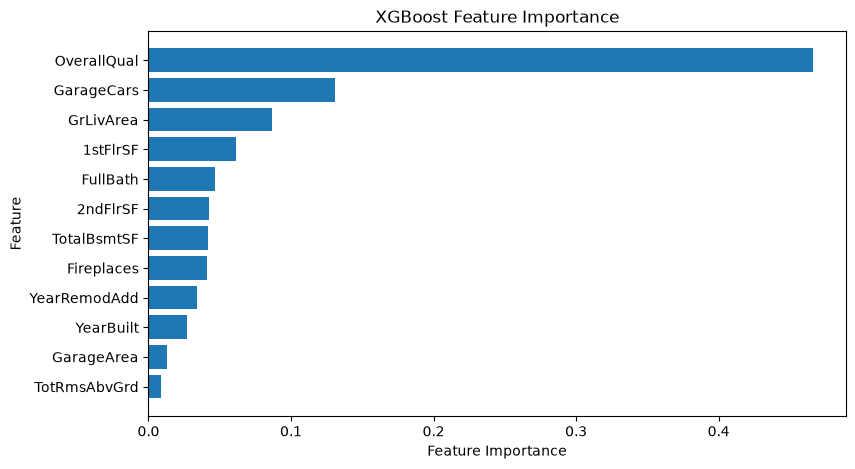

In [3]:
# TODO
# XGBoost의 Feature Importance를 표와 그래프로 확인하세요.
importance_df = pd.DataFrame({
    "feature": features,
    "importance": xgb_model.feature_importances_})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False)

display(importance_df)

plt.figure(figsize=(9, 5))
plt.barh(importance_df["feature"],
    importance_df["importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")
plt.gca().invert_yaxis()
plt.show()

#### OverallQual이 약 0.46으로 현재 모델에서 중요도를 차지하고 있다.
#### GarageCars가 약 0.13으로 현재 모델에서 두번째로 높은 중요도를 차지하고 있다.

### Q3. Feature Importance만으로는 알기 어려운 정보는 무엇인가요?
**답변:**  
#### 예측을 높이는지 낮추는지에 대한 방향성(음/양)
#### 특정 샘플 한 건에 대한 개별적인 기여도(중요도)에 근거

## 문제 2. TreeSHAP으로 전역 중요도를 확인하세요.

### 요구사항

1. `shap.TreeExplainer()`에 XGBoost 모델을 전달합니다.
2. Test 데이터의 SHAP 값을 계산합니다.
3. `shap.plots.bar()`로 전역 중요도를 확인합니다.
4. SHAP 절댓값의 평균도 계산하여 특성별 중요도를 DataFrame으로 정리합니다.
5. 상위 특성을 확인합니다.

### 확인 포인트

- SHAP은 각 특성이 예측값에 기여한 정도를 계산한다는 점을 이해했는가?
- 전역 SHAP에서는 여러 샘플의 기여도 크기를 종합해 전체 중요도를 볼 수 있는가?

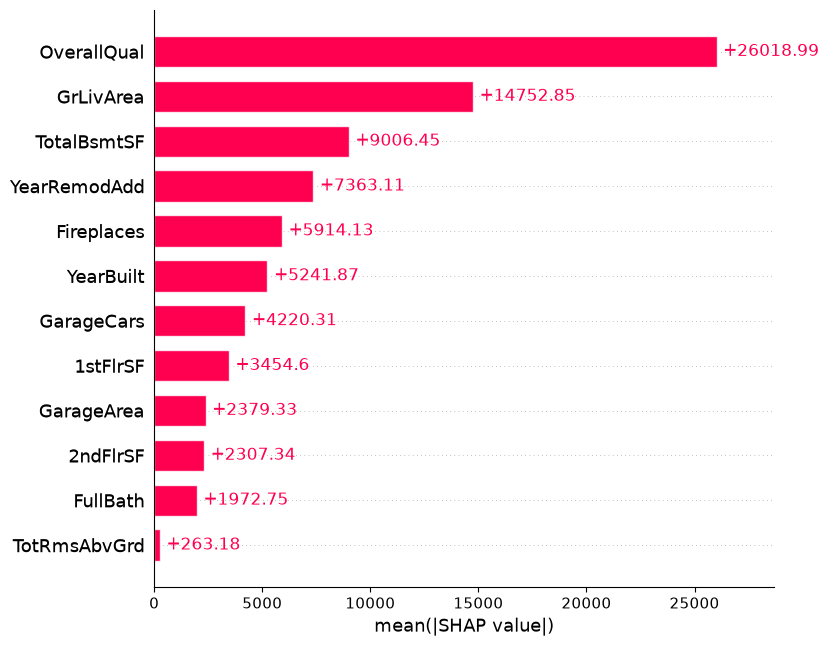

,feature,mean_abs_shap
0,OverallQual,26018.992188
1,GrLivArea,14752.852539
4,TotalBsmtSF,9006.452148
10,YearRemodAdd,7363.110352
11,Fireplaces,5914.131348
9,YearBuilt,5241.869141
2,GarageCars,4220.305664
5,1stFlrSF,3454.599609
3,GarageArea,2379.325684
6,2ndFlrSF,2307.338867


In [4]:
# TODO
# TreeSHAP을 이용해 XGBoost 모델의 전역 SHAP 중요도를 확인하세요.
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test)

shap.plots.bar(
    shap_values,
    max_display=12)

mean_abs_shap = np.abs(shap_values.values).mean(axis=0)

shap_global_df = pd.DataFrame({
    "feature": features,
    "mean_abs_shap": mean_abs_shap})

shap_global_df = shap_global_df.sort_values(
    "mean_abs_shap",
    ascending=False)
display(shap_global_df)

#### OverallQual 26,019의 의미
#### Test 주택 각각에서 품질에 배분된 SHAP 값의 절대값을 평균했더니 26,019 가격 단위였다 라는 뜻

#### 막대가 빨간색이고 *표시가 있는거 상승인가요?
#### -> 아니요. |SHAP value|절대값이기 떄문에 항상 예측이 양인 것을 의미하는 것은 아니다.

#### 가존 중요도와 순위가 다른 이유?
#### 기존 모델에서 Feature Importance에서는 GarageCars가 2위였는데
#### SHAP에서는 7위다.
#### SHAP에서는 Test 주택 예측 차이에 배분한 기여 크기를 평균하기 떄문에
#### 앞서 Feature Importance의 계산 원리와 집계 대상이 다르기 때문에 기준 중요도와 순위가 다를 수 있다.

### Q4. Feature Importance와 SHAP의 가장 큰 차이는 무엇인가요?
**답변:**
#### Feature Importance는 주로 모델 전체에서 중요도의 크기를 보여준다면
#### SHAP는 전역중요도, 개별 예측을 설명할 때, 각 특성의 양수/음수의 방향성을 보고 싶을 때까지 확인이 가능하다.

---
# 과제 1. 모델 비교·SHAP 해석과 특성 선택 전후 검증

## 배경
주택 가격 예측 모델을 성능과 학습 시간으로 비교하고, SHAP으로 예측 근거를 설명합니다. 이어서 중요한 특성을 선택했을 때 검증 성능이 어떻게 달라지는지 확인합니다.

> 필수 1·2는 연습용입니다. 아래 과제의 비교표·해석·코드를 제출하세요. 준비 단계의 `X_train`, `y_train`을 사용하되 과제용 모델을 새로 학습합니다. Test 결과로 모델이나 특성을 선택하지 않도록, Train 안에서 Validation을 분리합니다. 개별 주택 해석 대상도 Validation의 첫 번째 주택으로 맞춥니다.

## 요구사항

### 1. 같은 조건에서 모델 비교
1. `X_train`, `y_train`을 Train_sub / Validation으로 나누세요(`test_size=0.2`, `random_state=42`). 결측값이 있으면 Train_sub에서 구한 중앙값으로 두 데이터를 채우세요.
2. Random Forest(`n_estimators=200`)와 XGBoost(`n_estimators=200`, `learning_rate=0.05`, `max_depth=3`)를 같은 Train_sub에서 학습하세요. 두 모델 모두 `random_state=42`, `n_jobs=1`로 설정하세요.
3. 각 모델의 **fit에 걸린 시간**, Train_sub RMSE, Validation RMSE와 R²를 `model_comparison`으로 정리하세요. 시간은 같은 환경에서 측정하며, 한 번의 측정만으로 일반적인 속도 우열을 단정하지 마세요.
4. 예측 오차, 학습 시간, Train/Validation 오차 차이와 운영 목적을 근거로 우선 후보를 선택하세요. 모델 선택 결과와 관계없이 다음 해석은 XGBoost로 수행합니다.

### 2. Feature Importance와 SHAP 전역·지역 해석
5. 과제용 XGBoost의 `feature_importances_`와 **Train_sub의 평균 절댓값 SHAP**을 각각 순위로 정리하여 `importance_comparison`으로 비교하세요. 전역 SHAP 막대그래프도 제출하세요.
6. Validation의 첫 번째 주택의 실제 가격·예측가격을 확인하고 SHAP waterfall plot을 그리세요.
7. 해당 주택의 절댓값 SHAP 상위 5개 특성·특성값·SHAP 값을 `local_top5`로 정리하세요. 양수·음수의 의미를 설명하고 기준값 + 모든 SHAP 값의 합이 예측값과 거의 같은지 확인하세요.
8. 두 전역 중요도 산출 원리와 한계를 비교하고, 전역 순위와 개별 주택의 기여도가 다른 이유를 설명하세요.

### 3. 중요도에 근거한 특성 선택 및 검증
9. Train_sub의 평균 절댓값 SHAP이 높은 **상위 6개 특성**을 선택하세요. 특성 선택은 이번 과제의 특성 개선 시도입니다. 개수는 비교 결과를 보기 전에 6개로 고정합니다.
10. 선택한 특성만 사용하여 동일한 XGBoost 설정으로 다시 학습하세요. 기존 모델과 동일한 Train_sub / Validation 행을 사용하고, 특성 이외의 조건은 유지하세요.
11. 전체 특성 모델과 선택 특성 모델의 특성 수·학습 시간·Train RMSE·Validation RMSE·Validation R²를 `feature_comparison`으로 비교하세요. `기존 Validation RMSE - 선택 후 Validation RMSE`와 기존 대비 개선율(%)을 계산하세요.
12. 개선 여부와 채택 여부를 수치로 설명하세요. 성능이 나빠져도 원인 가능성과 한계를 타당하게 설명하면 됩니다. 검증 결과를 반복 확인하며 특성을 바꾸지 말고, 최종 일반화 성능 확인에는 별도 Test 평가가 필요함을 밝히세요.

## 해석 질문

### Q5. 전역 SHAP에서 가장 중요한 특성이 특정 주택에서도 반드시 가장 큰 영향을 주나요?
-> 아니요. 전역 SHAP은 모든 샘플의 기여도를 평균낸 값이고, 개별 주택의 기여도는 그 주택의 특성에 따라 값이 달라질 수 있다.

### Q6. SHAP 값이 양수/음수라는 것은 각각 무엇을 의미하나요?
-> 기준 값을 기준으로 SHAP 값을 더해서 양수는 예측값 상승 방향(+), 음수는 예측값 하락 방향(-)을 뜻한다.

### Q7. 두 모델 중 무엇을 우선 후보로 선택했나요? 성능·학습 시간·과적합 징후와 주택 가격 예측 업무를 연결하여 설명하세요.
-> XGBoost. Validation RMSE는 RandomForest 29,317, XGBoost 27,436로 XGBoost가 약 1,881 낮다. R²도 0.8670 대 0.8835로 XGBoost가 높다.
-> 학습시간 두 모델 모두 1초 이내로 한 번만 측정한 값이므로 일반적인 속도 우열로 단정하지 않는다.
-> Train–Validation RMSE 차이가 RandomForest 16,950, XGBoost 8,320으로 RandomForest가 약 2배다.
-> 주택 가격 예측은 근거를 설명해야 하는 경우가 많다. 검증 성능이 더 좋으면서 Train–Validation 간격도 절반 수준인 XGBoost가 업무에 사용하기에 더 적합할 것으로 보인다.

### Q8. Feature Importance와 평균 절댓값 SHAP의 계산 원리와 한계는 무엇이며, 실제 상위 특성 순위는 어떻게 다른가요?
-> Feature Importance : 분할할때 불순도가 줄어든 양을 전체 나무에 합산한다. 범주 수나 변수가 많을 때 과대평가하는 편향이 있음. 방향성, 개별 예측 근거를 알기가 어려움.
-> 평균 절댓값 SHAP : 각 특성 예측값을 분해한 뒤, 절대값을 평균한다. 절대값을 사용해 방향 정보가 사라질 수 있다. 

### Q9. 상위 6개 특성은 무엇이며, 선택 전후 RMSE 차이와 개선율은 얼마인가요? 이 시도를 채택할지와 판단의 한계를 설명하세요.
-> 'OverallQual', 'GrLivArea', 'TotalBsmtSF', 'YearRemodAdd', 'Fireplaces', 'YearBuilt'
RMSE 차이 −2,593.01, 개선율 −9.45% 로 오히려 악화되었다. 채택하지 않는다.

## 제출물 / 확인 포인트
- `model_comparison`, `importance_comparison`, 전역 SHAP 그래프
- 개별 주택의 실제값·예측값·waterfall plot·`local_top5`·SHAP 합 검증
- 선택한 6개 특성, `feature_comparison`, RMSE 차이와 개선율
- 계산 코드와 Q5~Q9 답변
- 동일한 검증 조건 유지, SHAP의 방향·전역/지역 구분, 관측한 개선 여부와 해석의 한계

In [5]:
# TODO 1: 같은 Train_sub / Validation으로 두 모델의 성능과 fit 시간을 비교하세요.

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

# 결측값은 Train_sub의 중앙값으로 두 데이터를 모두 채웁니다.
median_values = X_train_sub.median()

X_train_sub = X_train_sub.fillna(median_values)
X_val = X_val.fillna(median_values)

print("Train_sub 크기  :", X_train_sub.shape)
print("Validation 크기 :", X_val.shape)
print("남은 결측값     :", X_train_sub.isna().sum().sum(), X_val.isna().sum().sum())

task_models = {
    "RandomForest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        n_jobs=1
    )
}

rows = []

for name, model in task_models.items():
    start = time.time()
    model.fit(X_train_sub, y_train_sub)
    fit_seconds = time.time() - start

    train_pred = model.predict(X_train_sub)
    val_pred = model.predict(X_val)

    rows.append({
        "model": name,
        "fit_seconds": fit_seconds,
        "train_rmse": mean_squared_error(y_train_sub, train_pred) ** 0.5,
        "val_rmse": mean_squared_error(y_val, val_pred) ** 0.5,
        "val_r2": r2_score(y_val, val_pred)
    })

model_comparison = pd.DataFrame(rows)

print("\n[model_comparison]")
display(model_comparison)

task_rf = task_models["RandomForest"]
task_xgb = task_models["XGBoost"]

print("\nTrain-Validation RMSE 차이 (과적합 징후)")
for r in rows:
    print(r["model"], ":", r["val_rmse"] - r["train_rmse"])

Train_sub 크기  : (934, 12)
Validation 크기 : (234, 12)
남은 결측값     : 0 0

[model_comparison]


,model,fit_seconds,train_rmse,val_rmse,val_r2
0,RandomForest,0.407960,12367.658293,29317.762180,0.867024
1,XGBoost,0.029639,19116.641546,27436.846466,0.883539



Train-Validation RMSE 차이 (과적합 징후)
RandomForest : 16950.103887138044
XGBoost : 8320.20491997515


[importance_comparison]


,feature,importance,fi_rank,mean_abs_shap,shap_rank,rank_diff
0,OverallQual,0.427782,1,25416.365234,1,0
1,GrLivArea,0.078942,3,13777.564453,2,1
2,TotalBsmtSF,0.045537,6,9604.813477,3,3
3,YearRemodAdd,0.025395,9,7255.513184,4,5
4,Fireplaces,0.045971,5,6242.651367,5,0
5,YearBuilt,0.034376,7,6187.059570,6,1
6,GarageCars,0.205156,2,3490.014404,7,-5
7,1stFlrSF,0.050895,4,3446.147461,8,-4
8,GarageArea,0.016150,11,2788.530762,9,2
9,2ndFlrSF,0.033605,8,2005.598633,10,-2


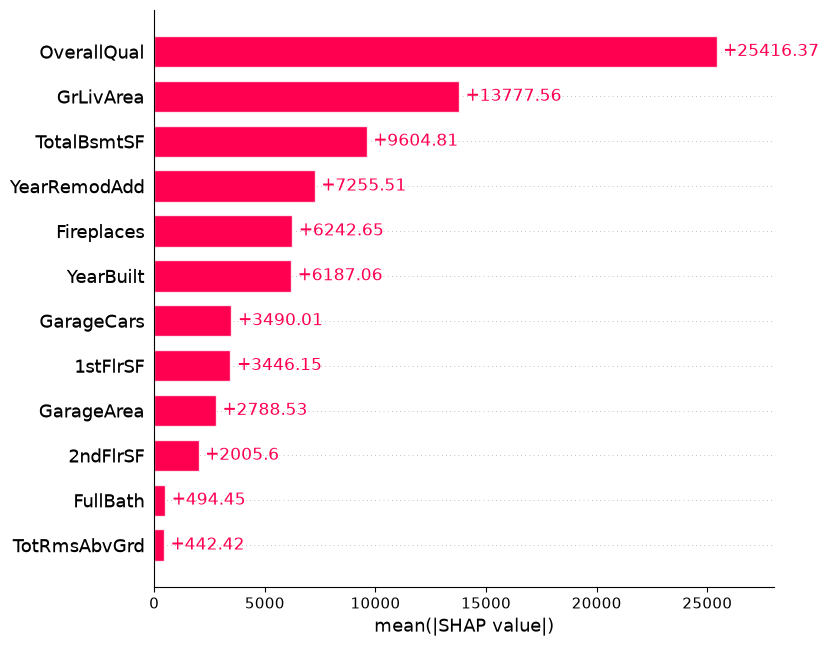

In [6]:
# TODO 2: 과제용 XGBoost의 Feature Importance, Train_sub 전역 SHAP, Validation 첫 주택의 지역 SHAP을 확인하세요.

# (1) Feature Importance 순위
fi_df = pd.DataFrame({
    "feature": features,
    "importance": task_xgb.feature_importances_
})

fi_df = fi_df.sort_values("importance", ascending=False).reset_index(drop=True)
fi_df["fi_rank"] = fi_df.index + 1

# (2) Train_sub 전역 SHAP 순위
explainer = shap.TreeExplainer(task_xgb)
shap_train = explainer(X_train_sub)

mean_abs_shap = np.abs(shap_train.values).mean(axis=0)

shap_df = pd.DataFrame({
    "feature": features,
    "mean_abs_shap": mean_abs_shap
})

shap_df = shap_df.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
shap_df["shap_rank"] = shap_df.index + 1

# (3) 두 순위를 나란히 비교
importance_comparison = fi_df.merge(shap_df, on="feature")
importance_comparison["rank_diff"] = importance_comparison["fi_rank"] - importance_comparison["shap_rank"]
importance_comparison = importance_comparison.sort_values("shap_rank").reset_index(drop=True)

print("[importance_comparison]")
display(importance_comparison)

# (4) 전역 SHAP 막대그래프
shap.plots.bar(shap_train, max_display=12)

[Validation 첫 번째 주택]
실제 가격: 140000
예측 가격: 149904.42
예측 오차: 9904.421875


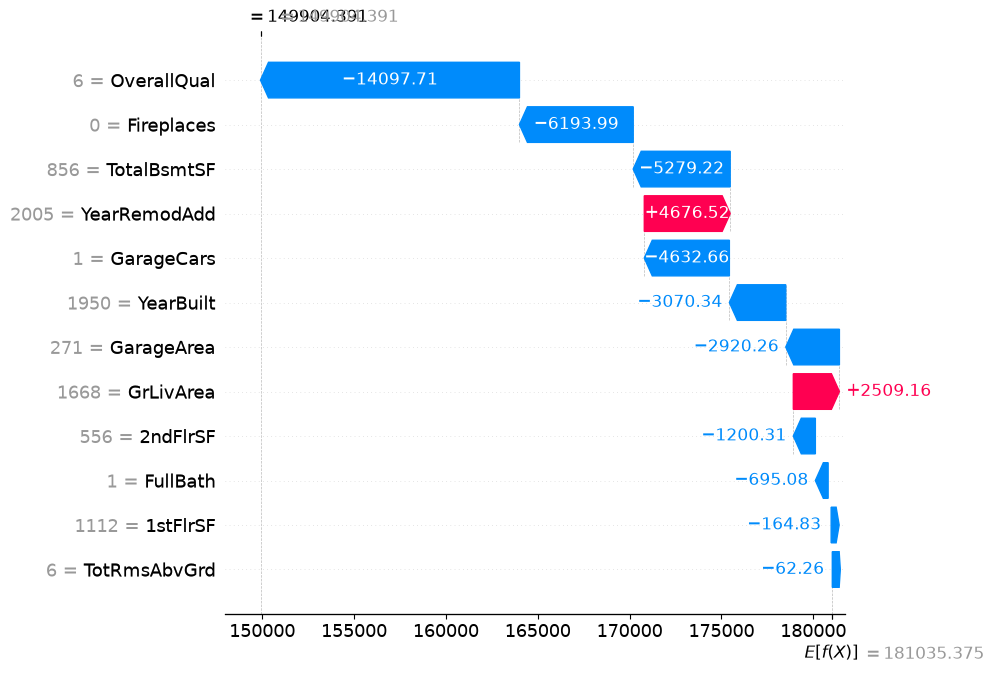

[local_top5]


,feature,value,shap_value,abs_shap,direction
0,OverallQual,6,-14097.710938,14097.710938,내림(-)
1,Fireplaces,0,-6193.989258,6193.989258,내림(-)
2,TotalBsmtSF,856,-5279.219727,5279.219727,내림(-)
3,YearRemodAdd,2005,4676.523438,4676.523438,올림(+)
4,GarageCars,1,-4632.663086,4632.663086,내림(-)



[SHAP 합 검증]
기준값(base value): 181035.38
SHAP 값 전체 합   : -31130.984
기준값 + SHAP 합  : 149904.39
모델 예측값       : 149904.42
둘의 차이         : 0.03125


In [7]:
# Validation 첫 번째 주택의 지역 해석
shap_val = explainer(X_val)

actual_price = y_val.iloc[0]
predicted_price = task_xgb.predict(X_val.iloc[[0]])[0]

print("[Validation 첫 번째 주택]")
print("실제 가격:", actual_price)
print("예측 가격:", predicted_price)
print("예측 오차:", predicted_price - actual_price)

shap.plots.waterfall(shap_val[0], max_display=12)

# 상위 5개 기여 특성 정리
local_top5 = pd.DataFrame({
    "feature": features,
    "value": X_val.iloc[0].values,
    "shap_value": shap_val.values[0]
})

local_top5["abs_shap"] = local_top5["shap_value"].abs()
local_top5 = local_top5.sort_values("abs_shap", ascending=False).head(5).reset_index(drop=True)
local_top5["direction"] = np.where(local_top5["shap_value"] > 0, "올림(+)", "내림(-)")

print("[local_top5]")
display(local_top5)

# 기준값 + 모든 SHAP 값의 합 = 예측값 확인
base_value = shap_val.base_values[0]
shap_sum = shap_val.values[0].sum()

print("\n[SHAP 합 검증]")
print("기준값(base value):", base_value)
print("SHAP 값 전체 합   :", shap_sum)
print("기준값 + SHAP 합  :", base_value + shap_sum)
print("모델 예측값       :", predicted_price)
print("둘의 차이         :", abs((base_value + shap_sum) - predicted_price))

In [8]:
# TODO 3: Train_sub SHAP 상위 6개 특성으로 재학습하고 동일 Validation에서 전후 성능을 비교하세요.
top6_features = shap_df.head(6)["feature"].tolist()

print("[선택한 상위 6개 특성]")
print(top6_features)

X_train_sub_top6 = X_train_sub[top6_features]
X_val_top6 = X_val[top6_features]

model_top6 = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    n_jobs=1
)

start = time.time()
model_top6.fit(X_train_sub_top6, y_train_sub)
top6_fit_seconds = time.time() - start

full_row = model_comparison[model_comparison["model"] == "XGBoost"].iloc[0]

feature_comparison = pd.DataFrame([
    {
        "model": "전체 특성(12개)",
        "n_features": len(features),
        "fit_seconds": full_row["fit_seconds"],
        "train_rmse": full_row["train_rmse"],
        "val_rmse": full_row["val_rmse"],
        "val_r2": full_row["val_r2"]
    },
    {
        "model": "선택 특성(6개)",
        "n_features": len(top6_features),
        "fit_seconds": top6_fit_seconds,
        "train_rmse": mean_squared_error(y_train_sub, model_top6.predict(X_train_sub_top6)) ** 0.5,
        "val_rmse": mean_squared_error(y_val, model_top6.predict(X_val_top6)) ** 0.5,
        "val_r2": r2_score(y_val, model_top6.predict(X_val_top6))
    }
])

print("\n[feature_comparison]")
display(feature_comparison)

rmse_diff = feature_comparison.loc[0, "val_rmse"] - feature_comparison.loc[1, "val_rmse"]
improve_pct = rmse_diff / feature_comparison.loc[0, "val_rmse"] * 100

print("\n기존 Validation RMSE - 선택 후 Validation RMSE =", rmse_diff)
print("개선율(%) =", improve_pct)

[선택한 상위 6개 특성]
['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'YearRemodAdd', 'Fireplaces', 'YearBuilt']

[feature_comparison]


,model,n_features,fit_seconds,train_rmse,val_rmse,val_r2
0,전체 특성(12개),12,0.029639,19116.641546,27436.846466,0.883539
1,선택 특성(6개),6,0.020139,20282.480322,30029.857143,0.860486



기존 Validation RMSE - 선택 후 Validation RMSE = -2593.0106764965094
개선율(%) = -9.450833497602664


## Q5~Q9 답변

### Q5. 전역 SHAP에서 가장 중요한 특성이 특정 주택에서도 반드시 가장 큰 영향을 주나요?
-> 아니요. 전역 SHAP은 모든 샘플의 기여도를 평균낸 값이고, 개별 주택의 기여도는 그 주택의 특성에 따라 값이 달라질 수 있다.

### Q6. SHAP 값이 양수/음수라는 것은 각각 무엇을 의미하나요?
-> 기준 값을 기준으로 SHAP 값을 더해서 양수는 예측값 상승 방향(+), 음수는 예측값 하락 방향(-)을 뜻한다.

### Q7. 두 모델 중 무엇을 우선 후보로 선택했나요? 성능·학습 시간·과적합 징후와 주택 가격 예측 업무를 연결하여 설명하세요.
-> XGBoost. Validation RMSE는 RandomForest 29,317, XGBoost 27,436로 XGBoost가 약 1,881 낮다. R²도 0.8670 대 0.8835로 XGBoost가 높다.
-> 학습시간 두 모델 모두 1초 이내로 한 번만 측정한 값이므로 일반적인 속도 우열로 단정하지 않는다.
-> Train–Validation RMSE 차이가 RandomForest 16,950, XGBoost 8,320으로 RandomForest가 약 2배다.
-> 주택 가격 예측은 근거를 설명해야 하는 경우가 많다. 검증 성능이 더 좋으면서 Train–Validation 간격도 절반 수준인 XGBoost가 업무에 사용하기에 더 적합할 것으로 보인다.

### Q8. Feature Importance와 평균 절댓값 SHAP의 계산 원리와 한계는 무엇이며, 실제 상위 특성 순위는 어떻게 다른가요?
-> Feature Importance : 분할할때 불순도가 줄어든 양을 전체 나무에 합산한다. 범주 수나 변수가 많을 때 과대평가하는 편향이 있음. 방향성, 개별 예측 근거를 알기가 어려움.
-> 평균 절댓값 SHAP : 각 특성 예측값을 분해한 뒤, 절대값을 평균한다. 절대값을 사용해 방향 정보가 사라질 수 있다. 

### Q9. 상위 6개 특성은 무엇이며, 선택 전후 RMSE 차이와 개선율은 얼마인가요? 이 시도를 채택할지와 판단의 한계를 설명하세요.
-> 'OverallQual', 'GrLivArea', 'TotalBsmtSF', 'YearRemodAdd', 'Fireplaces', 'YearBuilt'
RMSE 차이 −2,593.01, 개선율 −9.45% 로 오히려 악화되었다. 채택하지 않는다.

---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 배깅과 부스팅의 학습 방식 차이는 무엇인가요?
-> 배깅 -> 병렬, 독립 학습 후에 평균
-> 부스팅 -> 순차학습으로 이전 오차를 보완 

2. 배깅과 부스팅은 각각 편향과 분산 중 무엇을 줄이는 데 초점을 두나요?
-> 배깅 -> 주로 분산 감소
-> 부스팅 -> 주로 편향 감소

3. 튜닝 여력이 부족한 상황에서는 어떤 모델군을 먼저 고려할 수 있나요?
-> Random Forest를 베이스라인 후보로 고려할 수 있다.

4. Feature Importance의 가장 큰 한계는 무엇인가요?
-> 방향성, 개별 예측 근거를 알기가 어려움

5. SHAP의 전역 해석과 지역 해석은 무엇이 다른가요?
-> 전역 : 모델 전체에서 중요한 특성 파악
-> 지역 : 특정 샘플의 예측 근거 설명

6. SHAP 값의 양수와 음수는 무엇을 의미하나요?
-> 양수 -> 예측값 상승 방향
-> 음수 -> 예측값 하락 방향
